In [1]:
import sys, geopandas as gpd
#print(sys.executable)
#print(gpd.__version__)

import os
env = r"C:\Users\kadon\.conda\envs\targeting-task"
os.environ["PATH"] = env + r"\Library\bin;" + env + ";" + os.environ["PATH"]   # use this env's DLLs first
os.environ["PROJ_DATA"] = env + r"\Library\share\proj"
os.environ["PROJ_LIB"] = env + r"\Library\share\proj"
os.environ["GDAL_DATA"] = env + r"\Library\share\gdal"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # stops the common OpenMP clash from crashing the kernel

In [2]:
from pathlib import Path
for p in sorted(Path("data").rglob("*")):
    if p.is_file():
        print(p, f"{p.stat().st_size/1e3:.0f} KB")

data\Take home assignment.pdf 153 KB
data\task-aoi-parameters.csv 0 KB
data\task-aoi-passes.gpkg 11563 KB
data\task-aois.gpkg 106 KB


In [3]:
import pandas as pd
import geopandas as gpd
import pyogrio

# 1. Parameters CSV: size in bytes and contents
p = Path("data/task-aoi-parameters.csv")
print(p.stat().st_size, "bytes")
print(p.read_text()[:1000])

# 2. Layers in each GeoPackage
for f in ["data/task-aois.gpkg", "data/task-aoi-passes.gpkg"]:
    print(f)
    print(pyogrio.list_layers(f))

407 bytes
parameter,value,unit
window_start_utc,2026-09-14T00:00:00+00:00,
window_end_utc,2026-10-14T00:00:00+00:00,
sensor_mode,Stripmap,
incidence_angle_min,15,deg
incidence_angle_max,40,deg
frame_width,30,km
frame_length_rate_sso,7.14286,km/s
frame_length_rate_mio,6.5,km/s
imaging_seconds_min,10,s
imaging_seconds_max,120,s
imaging_seconds_max_per_orbit,120,s
min_seconds_between_acquisitions,50,"s (indicative)"

data/task-aois.gpkg
[['taskaois' 'Polygon']]
data/task-aoi-passes.gpkg
[['passes' 'Polygon']
 ['incidence_lines' 'LineString']
 ['pass_aois' None]]


In [4]:
passes = gpd.read_file("data/task-aoi-passes.gpkg", layer="passes")
inc = gpd.read_file("data/task-aoi-passes.gpkg", layer="incidence_lines")
pass_aois = gpd.read_file("data/task-aoi-passes.gpkg", layer="pass_aois")

for name, df in [("passes", passes), ("incidence_lines", inc), ("pass_aois", pass_aois)]:
    print(f"\n=== {name} === shape={df.shape} crs={getattr(df, 'crs', None)}")
    print(df.dtypes)
    print(df.drop(columns="geometry", errors="ignore").head(5).to_string())


=== passes === shape=(858, 9) crs=EPSG:4326
pass_id                            str
satellite_id                       str
orbit_type                         str
orbit_direction                    str
look_direction                     str
sensor_mode                        str
pass_start_utc     datetime64[ms, UTC]
pass_end_utc       datetime64[ms, UTC]
geometry                      geometry
dtype: object
  pass_id satellite_id orbit_type orbit_direction look_direction sensor_mode            pass_start_utc              pass_end_utc
0   P0001       SAT-14        SSO       Ascending          right    Stripmap 2026-09-14 01:56:20+00:00 2026-09-14 01:56:30+00:00
1   P0002       SAT-01        SSO       Ascending           left    Stripmap 2026-09-14 01:58:00+00:00 2026-09-14 01:58:10+00:00
2   P0003       SAT-05        SSO       Ascending           left    Stripmap 2026-09-14 02:18:50+00:00 2026-09-14 02:19:35+00:00
3   P0003       SAT-05        SSO       Ascending          right    Stripm

In [5]:
aois = gpd.read_file("data/task-aois.gpkg", layer="taskaois")
print(aois.crs, len(aois))
aois.drop(columns="geometry")

EPSG:4326 5


""
0
1
2
3
4


In [6]:
print(pass_aois.columns.tolist())
print(pass_aois.head().to_string())

# Is (pass_id, look_direction) unique in passes?
print("max rows per pass-side:", passes.groupby(["pass_id", "look_direction"]).size().max())

# Does every pass-side have incidence lines from 15 to 40 degrees?
print(inc.groupby(["pass_id", "look_direction"]).incidence_deg.agg(["min", "max", "count"]).describe())

# Constellation make-up
print(passes.groupby("orbit_type").satellite_id.nunique())
print(passes.groupby(["orbit_type", "orbit_direction", "look_direction"]).size())

['pass_id', 'look_direction', 'aoi_id', 'start_utc', 'end_utc', 'duration_s']
  pass_id look_direction  aoi_id                 start_utc                   end_utc  duration_s
0   P0001          right       3 2026-09-14 01:56:20+00:00 2026-09-14 01:56:30+00:00          10
1   P0002           left       3 2026-09-14 01:58:00+00:00 2026-09-14 01:58:10+00:00          10
2   P0003           left       5 2026-09-14 02:18:50+00:00 2026-09-14 02:19:35+00:00          45
3   P0003          right       3 2026-09-14 02:21:20+00:00 2026-09-14 02:21:35+00:00          15
4   P0004           left       2 2026-09-14 02:46:05+00:00 2026-09-14 02:46:35+00:00          30
max rows per pass-side: 1
         min    max  count
count  858.0  858.0  858.0
mean    15.0   40.0   26.0
std      0.0    0.0    0.0
min     15.0   40.0   26.0
25%     15.0   40.0   26.0
50%     15.0   40.0   26.0
75%     15.0   40.0   26.0
max     15.0   40.0   26.0
orbit_type
MIO     2
SSO    17
Name: satellite_id, dtype: int64
orbit_t

In [7]:
start = pd.Timestamp("2026-09-14", tz="UTC")

pa = pass_aois.merge(
    passes[["pass_id", "look_direction", "satellite_id", "orbit_type", "orbit_direction"]],
    on=["pass_id", "look_direction"],
)
print(len(pass_aois), len(pa))  # should match

pa["week"] = (pa.start_utc - start).dt.days // 7 + 1        # weeks 1-4, plus week 5 = the last 2 days
pa["geom"] = pa.orbit_direction.str[:3] + "-" + pa.look_direction   # e.g. "Asc-left"

counts = pa.pivot_table(index=["aoi_id", "geom"], columns="week",
                        values="pass_id", aggfunc="count", fill_value=0)
print(counts.to_string())

# How much imaging time each AOI gets
print(pa.groupby("aoi_id").duration_s.describe().to_string())

1128 1128
week               1   2   3   4   5
aoi_id geom                         
1      Asc-left   20  17  15  29   3
       Asc-right  17  20  18  20  10
       Des-left   16  22  21  24   8
       Des-right  15  19  12  19   7
2      Asc-left   17  14  13  18   7
       Asc-right   5  10  10  12   2
       Des-left    7   8  10  10   2
       Des-right  13  17  17  18   7
3      Asc-left    9  11   6   5   1
       Asc-right  16  12   8   9   1
       Des-left    6   9   8  10   4
       Des-right  15   9  10   8   2
4      Asc-left   12  18   7   7   2
       Asc-right  15  12  12  22   3
       Des-left    7  10   7  10   1
       Des-right  17   8   5  10   3
5      Asc-left   14  14  10  18   1
       Asc-right  14  17  11  18   6
       Des-left    7  16  11  19   6
       Des-right  13  12  12  10   3
        count       mean        std  min    25%   50%   75%   max
aoi_id                                                           
1       332.0  55.692771  14.716933  5.0  55

In [8]:
aois = gpd.read_file("data/task-aois.gpkg", layer="taskaois")
print(aois.crs, len(aois))
aois.drop(columns="geometry")

EPSG:4326 5


""
0
1
2
3
4


c:\Users\kadon\.conda\envs\targeting-task\Library\share\proj
EPSG:32622
2    7569.041089
dtype: float64


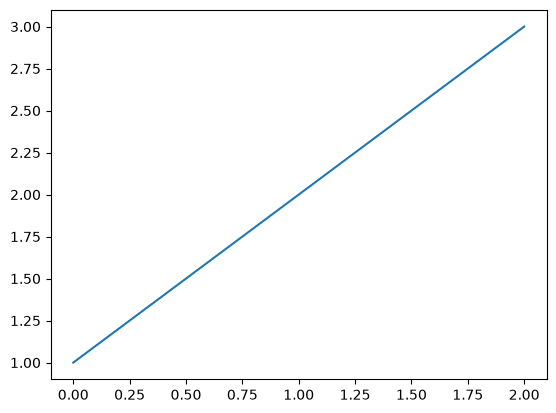

In [9]:
import pyproj
print(pyproj.datadir.get_data_dir())

utm = aois.iloc[[2]].estimate_utm_crs()
print(utm)
print(aois.iloc[[2]].to_crs(utm).area / 1e6)   # AOI-3: about 7,600 km²

import matplotlib.pyplot as plt
plt.plot([1, 2, 3]); plt.show()

aoi_id
1    5
2    3
3    7
4    7
5    1
Name: duration_s, dtype: int64
             count      mean        std        min        25%        50%  \
orbit_type                                                                 
MIO          598.0 -1.910040  42.146618 -42.438141 -42.157874 -42.120461   
SSO         3354.0  0.234471  11.373869 -11.770041 -11.422515  10.833192   

                  75%        max  
orbit_type                        
MIO         42.041467  42.302119  
SSO         11.447275  11.734601  


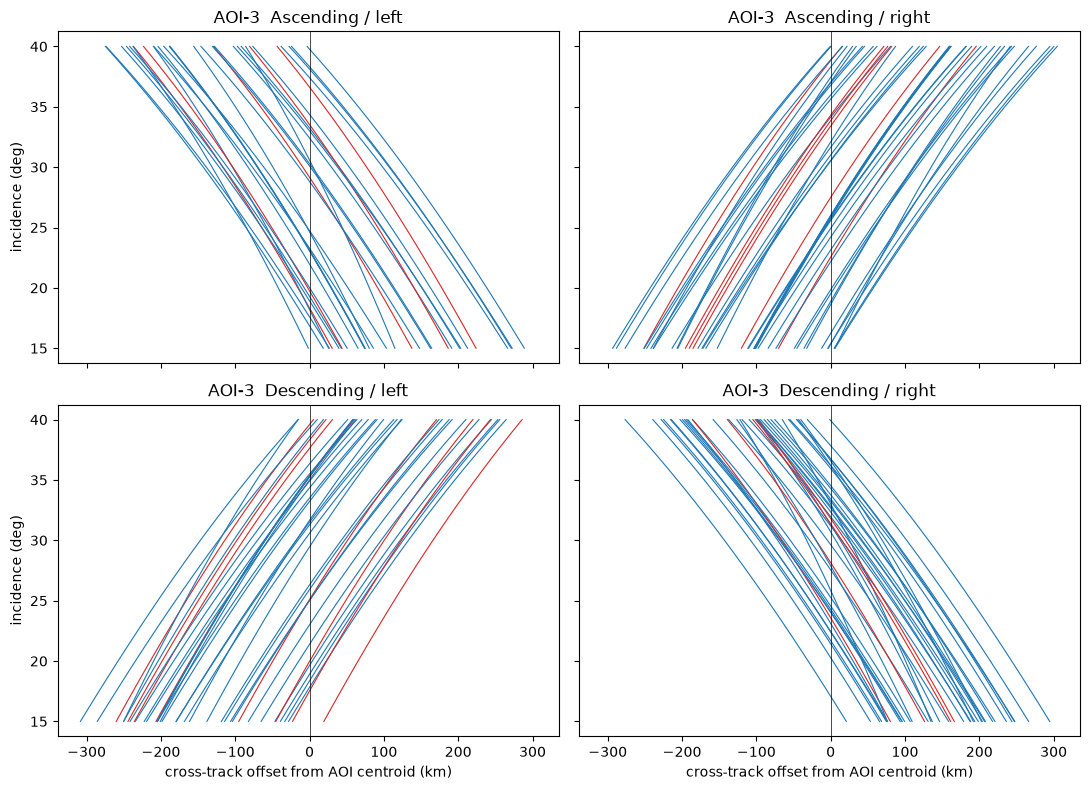

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Filter out unusable accesses (shorter than the 10 s minimum)
print((pa.duration_s < 10).groupby(pa.aoi_id).sum())
pa = pa[pa.duration_s >= 10].copy()

# 2. Cross-track offset of every incidence line relative to the AOI centroid
def line_offsets(aoi_id):
    aoi = aois.iloc[[aoi_id - 1]]                  # IDs follow feature order in the gpkg
    utm = aoi.estimate_utm_crs()
    c = aoi.to_crs(utm).geometry.iloc[0].centroid
    keys = pa.loc[pa.aoi_id == aoi_id, ["pass_id", "look_direction"]].drop_duplicates()
    lines = inc.merge(keys, on=["pass_id", "look_direction"]).to_crs(utm)

    rows = []
    for r in lines.itertuples():
        (x1, y1), (x2, y2) = r.geometry.coords[0], r.geometry.coords[-1]
        dx, dy = x2 - x1, y2 - y1
        if dy < 0:                                   # point every line north so the sign is consistent
            dx, dy = -dx, -dy
        L = np.hypot(dx, dy)
        offset_km = (dx * (c.y - y1) - dy * (c.x - x1)) / L / 1000   # + means the line is east of the centroid
        heading = np.degrees(np.arctan2(dx, dy))
        rows.append((r.pass_id, r.look_direction, r.incidence_deg, offset_km, heading))

    out = pd.DataFrame(rows, columns=["pass_id", "look_direction", "incidence_deg", "offset_km", "heading_deg"])
    return out.merge(passes[["pass_id", "look_direction", "orbit_type", "orbit_direction"]],
                     on=["pass_id", "look_direction"]).assign(aoi_id=aoi_id)

off3 = line_offsets(3)

# 3. Plot: one curve per pass-side, incidence angle vs ground position
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, (g, d) in zip(axes.flat, off3.groupby(["orbit_direction", "look_direction"])):
    for (pid, ot), p in d.groupby(["pass_id", "orbit_type"]):
        ax.plot(p.offset_km, p.incidence_deg, lw=0.8, color="C0" if ot == "SSO" else "C3")
    ax.axvline(0, color="k", lw=0.5)
    ax.set_title(f"AOI-3  {g[0]} / {g[1]}")
for ax in axes[1]: ax.set_xlabel("cross-track offset from AOI centroid (km)")
for ax in axes[:, 0]: ax.set_ylabel("incidence (deg)")
plt.tight_layout()

print(off3.groupby("orbit_type").heading_deg.describe())

In [22]:
from shapely import affinity
from shapely.geometry import box

TOL = 3
WEEKS = [1, 2, 3, 4]

def band_table(aoi_id, off, tol=TOL):
    aoi = aois.iloc[[aoi_id - 1]]
    geom = aoi.to_crs(aoi.estimate_utm_crs()).geometry.iloc[0]
    c = geom.centroid
    t = pa.loc[pa.aoi_id == aoi_id, ["pass_id", "look_direction", "week"]].set_index(["pass_id", "look_direction"])

    rows = []
    for g, d in off.groupby(["orbit_type", "orbit_direction", "look_direction"]):
        h = d.heading_deg.median()
        rot = affinity.rotate(geom, h, origin=c)          # rotate the AOI so its x axis = cross-track offset
        xmin, ymin, xmax, ymax = rot.bounds
        centres = np.arange((xmin - c.x) / 1000 + 15, (xmax - c.x) / 1000 + 15, 30)

        # incidence angle of each pass-side at each band centre (NaN if out of 15-40 deg range)
        inc_at = {}
        for key, p in d.groupby(["pass_id", "look_direction"]):
            p = p.sort_values("offset_km")
            inc_at[key] = np.interp(centres, p.offset_km, p.incidence_deg, left=np.nan, right=np.nan)
        I = pd.DataFrame(inc_at, index=centres).T
        I.index.names = ["pass_id", "look_direction"]
        I = I.join(t)

        for x in centres:
            band = box(c.x + (x - 15) * 1000, ymin - 1, c.x + (x + 15) * 1000, ymax + 1)
            frac = rot.intersection(band).area / geom.area

            best = None
            for th0 in range(15, 41):
                hits = I.loc[(I[x] - th0).abs() <= tol, "week"]
                wk = hits.value_counts()
                score = (sum(wk.get(w, 0) > 0 for w in WEEKS), len(hits))
                if best is None or score > best[0]:
                    best = (score, th0, [wk.get(w, 0) for w in WEEKS], list(zip(hits.index, hits)))
            (weeks_hit, n), th0, wk, hit_list = best
            rows.append(dict(orbit_type=g[0], orbit_dir=g[1], look=g[2], band_km=round(x),
                             area_frac=round(frac, 3), baseline_deg=th0, weeks_hit=weeks_hit,
                             **{f"w{w}": k for w, k in zip(WEEKS, wk)}, hits=hit_list))
    return pd.DataFrame(rows)

bt3 = band_table(3, off3)
print(bt3.to_string())

# Weekly coverage if the whole AOI is stacked in one geometry family
cov = bt3.groupby(["orbit_type", "orbit_dir", "look"]).apply(
    lambda d: pd.Series({f"w{w}": d.loc[d[f"w{w}"] > 0, "area_frac"].sum() for w in WEEKS}))
print(cov.round(2).to_string())

   orbit_type   orbit_dir   look  band_km  area_frac  baseline_deg  weeks_hit  w1  w2  w3  w4                                                                                                                                                                                                                                                                                                                                                                                        hits
0         MIO   Ascending   left      -51      0.130            22          2   1   0   0   1                                                                                                                                                                                                                                                                                                                                                    [((P0067, left), 1), ((P0488, left), 4)]
1         MIO   Ascending   left      -21      0.304

In [24]:
def max_matching(options):
    """options: one set of usable pass keys per band. Returns {pass: band} for the bands that each get a distinct pass."""
    owner = {}                                   # pass -> band
    def assign(b, seen):
        for p in options[b]:
            if p not in seen:
                seen.add(p)
                if p not in owner or assign(owner[p], seen):
                    owner[p] = b
                    return True
        return False
    for b in range(len(options)):
        assign(b, set())
    return owner

In [16]:
print(weekly_coverage(band_table(3, off3, tol=5)).round(2).to_string())

                        w1    w2    w3    w4
MIO Ascending  left   0.13  0.64  0.30  0.13
               right  0.00  0.13  0.44  0.13
    Descending left   0.23  0.12  0.23  0.12
               right  0.12  0.00  0.49  0.12
SSO Ascending  left   1.00  1.00  1.00  0.54
               right  1.00  1.00  1.00  1.00
    Descending left   0.49  1.00  1.00  1.00
               right  1.00  1.00  0.96  1.00


In [17]:
from itertools import product

def mixed_design(bt, orbit_type, orbit_dir):
    """Try every fixed left/right choice per band; return the one with the best worst week."""
    d = bt[(bt.orbit_type == orbit_type) & (bt.orbit_dir == orbit_dir)]
    bands = sorted(d.band_km.unique())
    best = None
    for choice in product(["left", "right"], repeat=len(bands)):
        rows = [d[(d.band_km == b) & (d.look == lk)].iloc[0] for b, lk in zip(bands, choice)]
        cov = []
        for w in WEEKS:
            options = [{key[0] for key, wk in r.hits if wk == w} for r in rows]   # key[0] = pass_id
            cov.append(sum(rows[i].area_frac for i in max_matching(options)))
        if best is None or min(cov) > min(best[1]):
            best = (choice, [round(c, 2) for c in cov])
    return best

for od in ["Ascending", "Descending"]:
    print(od, mixed_design(bt3, "SSO", od))

Ascending (('left', 'right', 'left'), [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)])
Descending (('left', 'right', 'left', 'right'), [np.float64(0.73), np.float64(1.0), np.float64(0.96), np.float64(1.0)])


In [25]:
from itertools import product

CADENCE = {1: 30, 2: 14, 3: 7, 4: 14, 5: 7}            # cycle length in days
MIN_COV = {1: 0.90, 2: 0.95, 3: 1.00, 4: 0.95, 5: 0.90}

def add_cycles(days):
    n = 30 // days                                      # whole cycles in the 30-day window
    c = (pa.start_utc - start).dt.days // days + 1
    return c.where(c <= n), list(range(1, n + 1))       # NaN = spare days after the last full cycle

def band_table(aoi_id, off, cycles, tol=3):
    aoi = aois.iloc[[aoi_id - 1]]
    geom = aoi.to_crs(aoi.estimate_utm_crs()).geometry.iloc[0]
    c = geom.centroid
    t = pa.loc[pa.aoi_id == aoi_id, ["pass_id", "look_direction", "cycle"]].set_index(["pass_id", "look_direction"])

    rows = []
    for g, d in off.groupby(["orbit_type", "orbit_direction", "look_direction"]):
        h = d.heading_deg.median()
        rot = affinity.rotate(geom, h, origin=c)        # rotate the AOI so its x axis = cross-track offset
        xmin, ymin, xmax, ymax = rot.bounds
        centres = np.arange((xmin - c.x) / 1000 + 15, (xmax - c.x) / 1000 + 15, 30)

        inc_at = {}
        for key, p in d.groupby(["pass_id", "look_direction"]):
            p = p.sort_values("offset_km")
            inc_at[key] = np.interp(centres, p.offset_km, p.incidence_deg, left=np.nan, right=np.nan)
        I = pd.DataFrame(inc_at, index=centres).T
        I.index.names = ["pass_id", "look_direction"]
        I = I.join(t)

        for x in centres:
            band = box(c.x + (x - 15) * 1000, ymin - 1, c.x + (x + 15) * 1000, ymax + 1)
            frac = rot.intersection(band).area / geom.area
            best = None                                 # baseline angle that hits the most cycles
            for th0 in range(15, 41):
                hits = I.loc[(I[x] - th0).abs() <= tol, "cycle"].dropna()
                score = (hits.nunique(), len(hits))
                if best is None or score > best[0]:
                    best = (score, th0, list(zip(hits.index, hits)))
            (n_cyc, n), th0, hit_list = best
            rows.append(dict(orbit_type=g[0], orbit_dir=g[1], look=g[2], band_km=round(x),
                             area_frac=round(frac, 3), baseline_deg=th0, cycles_hit=n_cyc, hits=hit_list))
    return pd.DataFrame(rows)

def coverage(rows, cycles):
    """Coverage per cycle for a stack design (one row per band), with one distinct pass per band."""
    out = []
    for w in cycles:
        options = [{key[0] for key, cyc in r.hits if cyc == w} for r in rows]   # key[0] = pass_id
        out.append(round(min(1, sum(rows[i].area_frac for i in set(max_matching(options).values()))), 2))
    return out

def single_family(bt, cycles):
    return {g: coverage([r for _, r in d.iterrows()], cycles)
            for g, d in bt.groupby(["orbit_type", "orbit_dir", "look"])}

def mixed_design(bt, orbit_type, orbit_dir, cycles):
    """Try every fixed left/right choice per band; return the one with the best worst cycle."""
    L = bt[(bt.orbit_type == orbit_type) & (bt.orbit_dir == orbit_dir) & (bt.look == "left")].sort_values("band_km")
    R = bt[(bt.orbit_type == orbit_type) & (bt.orbit_dir == orbit_dir) & (bt.look == "right")].sort_values("band_km")
    if len(L) != len(R):
        return None
    best = None
    for choice in product(["left", "right"], repeat=len(L)):
        rows = [(L if lk == "left" else R).iloc[i] for i, lk in enumerate(choice)]
        cov = coverage(rows, cycles)
        if best is None or min(cov) > min(best[1]):
            best = (choice, cov)
    return best

In [19]:
results = {}
for a in [1, 2, 3, 4, 5]:
    pa["cycle"], cycles = add_cycles(CADENCE[a])
    bt = band_table(a, line_offsets(a), cycles)
    single = single_family(bt, cycles)
    mixed = {od: mixed_design(bt, "SSO", od, cycles) for od in ["Ascending", "Descending"]}
    results[a] = dict(bt=bt, single=single, mixed=mixed)

    best_single = max(min(v) for v in single.values())
    best_mixed = max(min(m[1]) for m in mixed.values() if m)
    print(f"\nAOI-{a}: every {CADENCE[a]} d, need {MIN_COV[a]:.0%}, {len(bt) // 8}-ish bands | "
          f"best single-family worst cycle {best_single:.0%} | best mixed-look worst cycle {best_mixed:.0%}")
    for g, v in single.items():
        print("   ", g, v)
    for od, m in mixed.items():
        print("    mixed SSO", od, m)


AOI-1: every 30 d, need 90%, 16-ish bands | best single-family worst cycle 100% | best mixed-look worst cycle 101%
    ('MIO', 'Ascending', 'left') [0.38]
    ('MIO', 'Ascending', 'right') [0.44]
    ('MIO', 'Descending', 'left') [0.48]
    ('MIO', 'Descending', 'right') [0.41]
    ('SSO', 'Ascending', 'left') [1.0]
    ('SSO', 'Ascending', 'right') [1.0]
    ('SSO', 'Descending', 'left') [1.0]
    ('SSO', 'Descending', 'right') [1.0]
    mixed SSO Ascending (('left', 'left', 'left', 'left', 'left', 'left', 'left', 'left', 'left', 'left', 'left', 'left', 'left'), [np.float64(1.0)])
    mixed SSO Descending (('left', 'left', 'left', 'left', 'left', 'left', 'left', 'left', 'left', 'left', 'right', 'right', 'right', 'right', 'right'), [np.float64(1.01)])

AOI-2: every 14 d, need 95%, 8-ish bands | best single-family worst cycle 100% | best mixed-look worst cycle 100%
    ('MIO', 'Ascending', 'left') [0.23, 0.47]
    ('MIO', 'Ascending', 'right') [0.2, 0.47]
    ('MIO', 'Descending', 'lef

In [28]:
from collections import defaultdict

def design_rows(bt, od, choice):
    L = bt[(bt.orbit_type == "SSO") & (bt.orbit_dir == od) & (bt.look == "left")].sort_values("band_km")
    R = bt[(bt.orbit_type == "SSO") & (bt.orbit_dir == od) & (bt.look == "right")].sort_values("band_km")
    return [(L if lk == "left" else R).iloc[i] for i, lk in enumerate(choice)]

acc = pa.set_index(["pass_id", "look_direction", "aoi_id"])[["start_utc", "end_utc", "duration_s"]]

def allocate(order, budget=120, gap=50, drop=frozenset()):
    booked = defaultdict(list)                       # pass_id -> [(start, end, seconds)]
    g = pd.Timedelta(seconds=gap)
    out = {}
    for a in order:
        # each AOI's best stand-alone design (the mixed search includes the single-look designs)
        od, (choice, _) = max(((od, m) for od, m in results[a]["mixed"].items() if m), key=lambda x: min(x[1][1]))
        rows = design_rows(results[a]["bt"], od, choice)

        def ok(key):
            if key[0] in drop:
                return False
            s, e, dur = acc.loc[(key[0], key[1], a)]
            b = booked[key[0]]
            return (sum(x[2] for x in b) + dur <= budget and
                    all(s >= be + g or e + g <= bs for bs, be, _ in b))

        cov = []
        for w in range(1, 30 // CADENCE[a] + 1):
            lookups = [{key[0]: key for key, cyc in r.hits if cyc == w and ok(key)} for r in rows]
            owner = max_matching([set(l) for l in lookups])     # pass_id -> band
            for pid, b in owner.items():
                booked[pid].append(tuple(acc.loc[lookups[b][pid] + (a,)]))
            cov.append(round(min(1, sum(rows[b].area_frac for b in owner.values())), 2))
        out[a] = cov
    return out, booked

for order in [[3, 5, 4, 2, 1], [1, 2, 4, 5, 3]]:
    print("\npriority order:", order)
    res, _ = allocate(order)
    for a in sorted(res):
        print(f"  AOI-{a}: {res[a]}  need {MIN_COV[a]:.0%}  ->", "OK" if min(res[a]) >= MIN_COV[a] else "FAIL")


priority order: [3, 5, 4, 2, 1]
  AOI-1: [1]  need 90%  -> OK
  AOI-2: [1, 1]  need 95%  -> OK
  AOI-3: [1, 1, 1, 1]  need 100%  -> OK
  AOI-4: [1, 1]  need 95%  -> OK
  AOI-5: [1, 1, 1, 1]  need 90%  -> OK

priority order: [1, 2, 4, 5, 3]
  AOI-1: [1]  need 90%  -> OK
  AOI-2: [1, 1]  need 95%  -> OK
  AOI-3: [1, 1, 1, 1]  need 100%  -> OK
  AOI-4: [1, 1]  need 95%  -> OK
  AOI-5: [1, 1, 1, 1]  need 90%  -> OK


In [30]:
# How much capacity does the plan use?
res, booked = allocate([3, 5, 4, 2, 1])
secs = pd.Series({p: sum(x[2] for x in b) for p, b in booked.items() if b})
n_acq = pd.Series({p: len(b) for p, b in booked.items() if b})
print(f"passes used: {len(secs)} of {pa.pass_id.nunique()} | shared by 2+ AOIs: {(n_acq > 1).sum()} "
      f"| imaging seconds: total {secs.sum()}, max per pass {secs.max()}")

# Robustness: randomly drop a share of passes and see how often each AOI still succeeds
rng = np.random.default_rng(0)
pids = pa.pass_id.unique()
for loss in [0.1, 0.2, 0.3]:
    wins = pd.Series(0, index=[1, 2, 3, 4, 5])
    for _ in range(30):
        drop = set(rng.choice(pids, int(loss * len(pids)), replace=False))
        r, _ = allocate([3, 5, 4, 2, 1], drop=drop)
        wins += pd.Series({a: min(v) >= MIN_COV[a] for a, v in r.items()})
    print(f"{loss:.0%} of passes unavailable -> success rate:", (wins / 30).round(2).to_dict())

passes used: 76 of 554 | shared by 2+ AOIs: 6 | imaging seconds: total 2885, max per pass 75
10% of passes unavailable -> success rate: {1: 1.0, 2: 0.7, 3: 0.63, 4: 0.63, 5: 0.3}
20% of passes unavailable -> success rate: {1: 1.0, 2: 0.37, 3: 0.3, 4: 0.5, 5: 0.17}
30% of passes unavailable -> success rate: {1: 1.0, 2: 0.07, 3: 0.3, 4: 0.17, 5: 0.03}


In [31]:
def try_design(a, rows, booked, drop, budget=120, gap=50, commit=False):
    g = pd.Timedelta(seconds=gap)
    def ok(key):
        if key[0] in drop:
            return False
        s, e, dur = acc.loc[(key[0], key[1], a)]
        b = booked[key[0]]
        return (sum(x[2] for x in b) + dur <= budget and
                all(s >= be + g or e + g <= bs for bs, be, _ in b))
    cov = []
    for w in range(1, 30 // CADENCE[a] + 1):
        lookups = [{key[0]: key for key, cyc in r.hits if cyc == w and ok(key)} for r in rows]
        owner = max_matching([set(l) for l in lookups])
        if commit:
            for pid, b in owner.items():
                booked[pid].append(tuple(acc.loc[lookups[b][pid] + (a,)]))
        cov.append(round(min(1, sum(rows[b].area_frac for b in owner.values())), 2))
    return cov

def candidate_designs(a):
    """All single SSO families plus the best mixed-look designs for this AOI."""
    sso = results[a]["bt"].query("orbit_type == 'SSO'")
    designs = [[r for _, r in d.sort_values("band_km").iterrows()] for _, d in sso.groupby(["orbit_dir", "look"])]
    designs += [design_rows(results[a]["bt"], od, m[0]) for od, m in results[a]["mixed"].items() if m]
    return designs

def allocate_replan(order, drop=frozenset()):
    """Like allocate, but each AOI picks whichever design works best given the passes still available."""
    booked = defaultdict(list)
    out = {}
    for a in order:
        best = max(candidate_designs(a), key=lambda rows: min(try_design(a, rows, booked, drop)))
        out[a] = try_design(a, best, booked, drop, commit=True)
    return out, booked

def robustness(alloc_fn, trials=20):
    rng = np.random.default_rng(0)                      # same seed, so both methods face the same losses
    rows = []
    for loss in [0.1, 0.2, 0.3]:
        for _ in range(trials):
            drop = set(rng.choice(pids, int(loss * len(pids)), replace=False))
            r, _ = alloc_fn([3, 5, 4, 2, 1], drop=drop)
            for a, v in r.items():
                rows.append(dict(loss=loss, aoi=a, all_cycles=min(v) >= MIN_COV[a],
                                 cycles_met=np.mean([c >= MIN_COV[a] for c in v])))
    return pd.DataFrame(rows).groupby(["loss", "aoi"])[["all_cycles", "cycles_met"]].mean().unstack("loss").round(2)

print("FIXED design (losses happen mid-month):")
print(robustness(allocate).to_string())
print("\nRE-PLANNED design (losses known at planning time):")
print(robustness(allocate_replan).to_string())

FIXED design (losses happen mid-month):
     all_cycles            cycles_met            
loss        0.1  0.2   0.3        0.1   0.2   0.3
aoi                                              
1          1.00  1.0  1.00       1.00  1.00  1.00
2          0.70  0.4  0.10       0.85  0.70  0.55
3          0.55  0.3  0.15       0.85  0.79  0.60
4          0.70  0.5  0.35       0.85  0.75  0.60
5          0.25  0.2  0.00       0.80  0.69  0.51

RE-PLANNED design (losses known at planning time):
     all_cycles             cycles_met            
loss        0.1   0.2   0.3        0.1   0.2   0.3
aoi                                               
1          1.00  1.00  1.00       1.00  1.00  1.00
2          1.00  0.95  0.50       1.00  0.98  0.72
3          0.55  0.30  0.15       0.79  0.70  0.52
4          1.00  0.95  0.90       1.00  0.98  0.95
5          0.25  0.20  0.00       0.81  0.64  0.46


In [32]:
base_results, base_cad, base_cov = dict(results), dict(CADENCE), dict(MIN_COV)
offs = {a: line_offsets(a) for a in [3, 5]}

def rebuild(a, tol=3):
    pa["cycle"], cycles = add_cycles(CADENCE[a])
    bt = band_table(a, offs[a], cycles, tol=tol)
    results[a] = dict(bt=bt, single=single_family(bt, cycles),
                      mixed={od: mixed_design(bt, "SSO", od, cycles) for od in ["Ascending", "Descending"]})

scenarios = {
    "baseline":          dict(),
    "tolerance ±5°":     dict(tol=5),
    "biweekly cadence":  dict(cadence=14),
    "coverage -10 pts":  dict(min_cov={3: 0.90, 5: 0.80}),
}

summary = []
for name, s in scenarios.items():
    results.clear(); results.update(base_results)                 # reset to baseline
    CADENCE.update(base_cad); MIN_COV.update(base_cov)
    for a in [3, 5]:
        if "cadence" in s: CADENCE[a] = s["cadence"]
        if "min_cov" in s: MIN_COV[a] = s["min_cov"][a]
        if "tol" in s or "cadence" in s: rebuild(a, tol=s.get("tol", 3))
    no_loss, _ = allocate_replan([3, 5, 4, 2, 1])
    r = robustness(allocate_replan, trials=10)
    for a in [3, 5]:
        summary.append(dict(scenario=name, aoi=a, no_loss_ok=min(no_loss[a]) >= MIN_COV[a],
                            **{f"all_cycles@{l:.0%}": r.loc[a, ("all_cycles", l)] for l in [0.1, 0.2, 0.3]}))

results.clear(); results.update(base_results)                     # restore baseline
CADENCE.update(base_cad); MIN_COV.update(base_cov)
print(pd.DataFrame(summary).to_string(index=False))

        scenario  aoi  no_loss_ok  all_cycles@10%  all_cycles@20%  all_cycles@30%
        baseline    3        True             0.5             0.5             0.0
        baseline    5        True             0.2             0.1             0.0
   tolerance ±5°    3        True             1.0             0.9             0.7
   tolerance ±5°    5        True             0.5             0.3             0.0
biweekly cadence    3        True             1.0             1.0             0.9
biweekly cadence    5        True             1.0             1.0             0.9
coverage -10 pts    3        True             0.5             0.5             0.0
coverage -10 pts    5        True             1.0             0.8             0.8


In [33]:
Path("outputs").mkdir(exist_ok=True)
pd.DataFrame(summary).to_csv("outputs/sensitivity.csv", index=False)
robustness(allocate_replan, trials=20).to_csv("outputs/robustness_replan.csv")